# Performance test RAS versions

In [ ]:
from implementations.array_based import (
    RootishArrayStack,
    ImprovedRAS,
    FurtherImprovedRAS
)

In [2]:
import time
import random


def mixed_ops(cls, n, ops):
    s = cls()
    for i in range(n):
        s.add(i, i)
    start = time.time()
    for _ in range(ops):
        r = random.random()
        if r < 0.4:
            i = random.randrange(s.n)
            s.add(i, i)
        elif r < 0.8:
            if s.n > 0:
                i = random.randrange(s.n)
                s.remove(i)
        else:
            if s.n > 0:
                i = random.randrange(s.n)
                _ = s.get(i)
    return time.time() - start

In [3]:
rows = []

for n in [1000, 5000, 10000]:
    rows.append({
        "n iterations": n,
        "ras": mixed_ops(RootishArrayStack, n, 5000),
        "i-ras": mixed_ops(ImprovedRAS, n, 5000),
        "fi-ras": mixed_ops(FurtherImprovedRAS, n, 5000),
    })

In [4]:
import pandas as pd

bench_results = pd.DataFrame(rows)

bench_results = bench_results.set_index("n iterations")
bench_results = bench_results.T
bench_results = bench_results.rename_axis("ras-versions", axis="rows")
bench_results

n iterations,1000,5000,10000
ras-versions,,,
ras,2.295063,10.219300,20.350949
i-ras,1.301810,6.415690,12.949745
fi-ras,0.066191,0.125028,0.172846


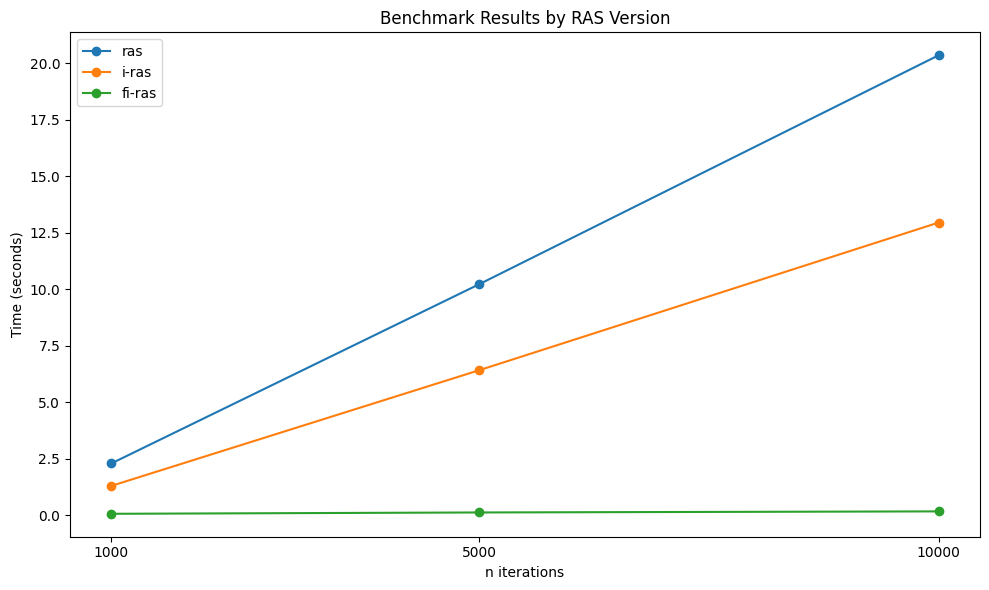

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for version in bench_results.index:
    plt.plot(bench_results.columns, bench_results.loc[version], marker='o', label=version)

plt.xlabel('n iterations')
plt.ylabel('Time (seconds)')
plt.title('Benchmark Results by RAS Version')
plt.legend()
plt.xticks(bench_results.columns)
plt.tight_layout()
plt.show()